# 02. EDA: Seasonality, Trend, and Price-Regime Context

This notebook investigates whether national monthly price series contain repeatable annual seasonal patterns. It applies robust STL to log prices, reports seasonal strength and seasonal amplitude, compares annual monthly profiles, and reserves space for conclusions. Labels and explanatory text are in English; product values retain the names supplied by the source.

In [1]:
from pathlib import Path
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the project root containing data/")
DATA_FILE = ROOT / "data" / "processed" / "avg_prices_monthly.csv"
RESULT_FILE = ROOT / "results" / "seasonality_rank.csv"
UKRAINE = "\u0423\u043a\u0440\u0430\u0457\u043d\u0430"
TARGET_GOODS = {
    "Potato": "\u041a\u0430\u0440\u0442\u043e\u043f\u043b\u044f",
    "Carrot": "\u041c\u043e\u0440\u043a\u0432\u0430",
    "Eggs": "\u042f\u0439\u0446\u044f",
    "Pasteurized milk": "\u041c\u043e\u043b\u043e\u043a\u043e \u043f\u0430\u0441\u0442\u0435\u0440\u0438\u0437\u043e\u0432\u0430\u043d\u0435 \u0436\u0438\u0440\u043d\u0456\u0441\u0442\u044e \u0434\u043e 2,6% \u0432\u043a\u043b\u044e\u0447\u043d\u043e",
    "A-95 gasoline": "\u0411\u0435\u043d\u0437\u0438\u043d \u0410-95",
    "Sunflower oil": "\u041e\u043b\u0456\u044f \u0441\u043e\u043d\u044f\u0448\u043d\u0438\u043a\u043e\u0432\u0430",
}
OPTIMIZATION_CANDIDATES = {
    "Beet": "\u0411\u0443\u0440\u044f\u043a",
    "White cabbage": "\u041a\u0430\u043f\u0443\u0441\u0442\u0430 \u0431\u0456\u043b\u043e\u043a\u0430\u0447\u0430\u043d\u043d\u0430",
    "Onion": "\u0426\u0438\u0431\u0443\u043b\u044f \u0440\u0456\u043f\u0447\u0430\u0441\u0442\u0430",
}
p = pd.read_csv(DATA_FILE, parse_dates=["date"])
ukraine = p[p["region"] == UKRAINE]
if ukraine.empty:
    raise ValueError("The published Ukraine aggregate was not found")
prices = (ukraine.pivot(index="date", columns="good", values="value")
    .sort_index().asfreq("MS"))
print("Monthly observations:", len(prices.index))
print("Period:", prices.index.min().date(), "to", prices.index.max().date())
print("Products:", len(prices.columns))

Monthly observations: 102
Period: 2017-01-01 to 2025-06-01
Products: 55


## 1. Visualize Prices Before Decomposition

A rising price level can dominate the appearance of a series. Plot the six selected prices separately (their source units differ), then inspect the seasonal decomposition on log prices. A change around 2022 may reflect structural and territorial changes or other shocks; the chart alone does not identify a cause.

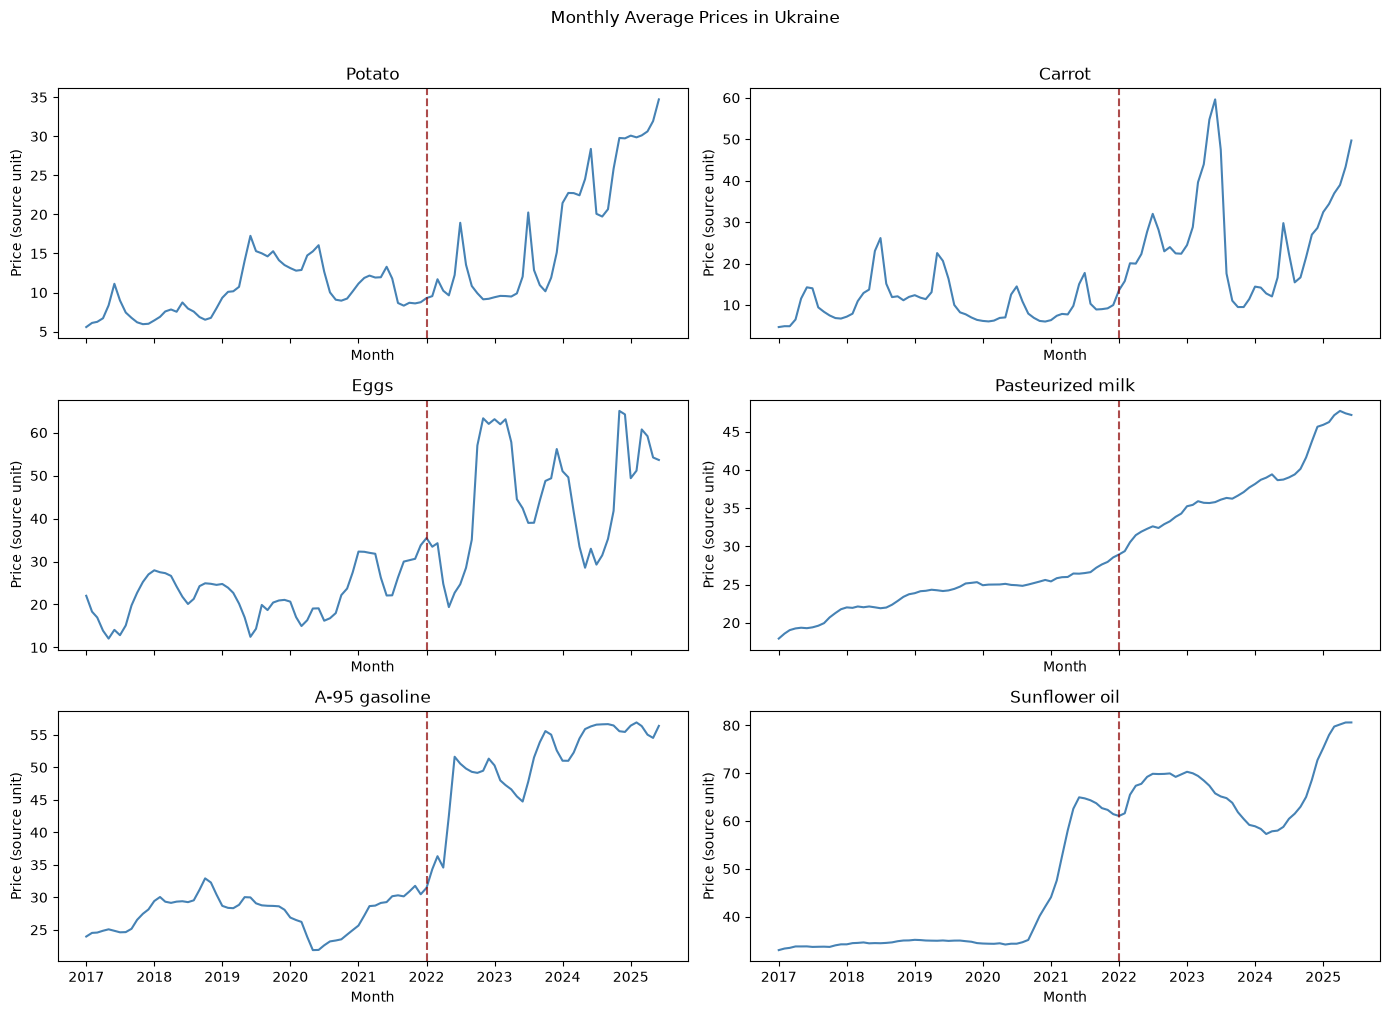

In [2]:
label_by_source = {source: label for label, source in TARGET_GOODS.items()}
missing_targets = set(TARGET_GOODS.values()) - set(prices.columns)
if missing_targets:
    raise ValueError(f"Selected products not present in the Ukraine panel: {missing_targets}")
target_prices = prices[list(TARGET_GOODS.values())].rename(columns=label_by_source)
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
for ax, label in zip(axes.ravel(), TARGET_GOODS):
    ax.plot(target_prices.index, target_prices[label], color="steelblue")
    ax.axvline(pd.Timestamp("2022-01-01"), color="darkred", linestyle="--", alpha=0.7)
    ax.set_title(label)
    ax.set_ylabel("Price (source unit)")
    ax.set_xlabel("Month")
fig.suptitle("Monthly Average Prices in Ukraine", y=1.01)
fig.tight_layout()
plt.show()

## 2. Robust STL Decomposition and Seasonal-Strength Metrics

For each product with a complete, strictly positive national series, decompose `log(price)` with robust STL and a 12-month period. `F_seasonal` and `F_trend` are descriptive variance-based strengths, **not p-values or hypothesis-test significance**. Report estimated annual seasonal amplitude as well: a smooth series can have high seasonal strength but economically small price swings.

In [3]:
rows = []
decompositions = {}
for good in prices.columns:
    series = prices[good].astype(float)
    missing = int(series.isna().sum())
    if missing or (series <= 0).any():
        rows.append({"good": good, "n_missing": missing,
                     "status": "Missing or non-positive values"})
        continue
    result = STL(np.log(series), period=12, robust=True).fit()
    decompositions[good] = result
    residual_var = result.resid.var()
    seasonal_denominator = (result.seasonal + result.resid).var()
    trend_denominator = (result.trend + result.resid).var()
    if seasonal_denominator <= 0 or trend_denominator <= 0:
        rows.append({"good": good, "n_missing": 0, "status": "Zero decomposition variance"})
        continue
    seasonal_strength = max(0.0, 1.0 - residual_var / seasonal_denominator)
    trend_strength = max(0.0, 1.0 - residual_var / trend_denominator)
    average_seasonal_effect = result.seasonal.groupby(result.seasonal.index.month).mean()
    rows.append({
        "good": good, "n_missing": 0, "status": "ok",
        "F_seasonal": seasonal_strength, "F_trend": trend_strength,
        "peak_month": int(average_seasonal_effect.idxmax()),
        "trough_month": int(average_seasonal_effect.idxmin()),
        "amplitude_pct": 100 * (np.exp(average_seasonal_effect.max() - average_seasonal_effect.min()) - 1),
    })
seasonality = pd.DataFrame(rows).sort_values("F_seasonal", ascending=False, na_position="last")
for col in ["F_seasonal", "F_trend"]:
    if col in seasonality:
        seasonality[col] = seasonality[col].round(2)
if "amplitude_pct" in seasonality:
    seasonality["amplitude_pct"] = seasonality["amplitude_pct"].round(1)
print("Seasonality metrics for all national product series:")
display(seasonality)
print("Series skipped because of missing/non-positive values:")
display(seasonality[seasonality["status"] != "ok"])

Seasonality metrics for all national product series:


,good,n_missing,status,F_seasonal,F_trend,peak_month,trough_month,amplitude_pct
41,Сири м’які жирні,0,ok,0.73,1.00,2.0,8.0,5.5
11,Дошкільна освіта,0,ok,0.70,1.00,1.0,12.0,7.8
25,Морква,0,ok,0.64,0.86,7.0,12.0,95.3
53,Яйця,0,ok,0.57,0.88,12.0,7.0,64.2
6,Буряк,0,ok,0.49,0.82,6.0,9.0,133.6
43,Стоматологічні послуги,0,ok,0.45,1.00,1.0,8.0,3.5
39,Сигарети з фільтром медіум класу,0,ok,0.41,1.00,9.0,1.0,1.4
40,Сигарети з фільтром преміум класу,0,ok,0.37,1.00,5.0,3.0,0.8
38,Сигарети з фільтром вітчизняних марок,0,ok,0.37,1.00,8.0,2.0,2.5
23,"Молоко пастеризоване жирністю до 2,6% включно",0,ok,0.35,1.00,12.0,6.0,3.1


Series skipped because of missing/non-positive values:


,good,n_missing,status,F_seasonal,F_trend,peak_month,trough_month,amplitude_pct
19,Крупи пшеничні,60,Missing or non-positive values,NaN,NaN,NaN,NaN,NaN
24,Молочні суміші для дитячого харчування,59,Missing or non-positive values,NaN,NaN,NaN,NaN,NaN
37,Сигарети без фільтру,42,Missing or non-positive values,NaN,NaN,NaN,NaN,NaN


In [4]:
selected_source_names = list(TARGET_GOODS.values()) + list(OPTIMIZATION_CANDIDATES.values())
selected_results = seasonality[seasonality["good"].isin(selected_source_names)].copy()
label_map = {**{v: k for k, v in TARGET_GOODS.items()},
             **{v: k for k, v in OPTIMIZATION_CANDIDATES.items()}}
selected_results["analysis_label"] = selected_results["good"].map(label_map)
display(selected_results[["analysis_label", "n_missing", "F_seasonal", "F_trend",
                          "peak_month", "trough_month", "amplitude_pct", "status"]]
        .sort_values("F_seasonal", ascending=False, na_position="last"))

,analysis_label,n_missing,F_seasonal,F_trend,peak_month,trough_month,amplitude_pct,status
25,Carrot,0,0.64,0.86,7.0,12.0,95.3,ok
53,Eggs,0,0.57,0.88,12.0,7.0,64.2,ok
6,Beet,0,0.49,0.82,6.0,9.0,133.6,ok
23,Pasteurized milk,0,0.35,1.00,12.0,6.0,3.1,ok
15,Potato,0,0.26,0.86,6.0,9.0,62.8,ok
50,Onion,0,0.12,0.74,5.0,11.0,108.8,ok
14,White cabbage,0,0.10,0.70,7.0,11.0,78.0,ok
4,A-95 gasoline,0,0.06,0.96,11.0,4.0,5.0,ok
26,Sunflower oil,0,0.00,0.93,6.0,10.0,6.7,ok


## 3. Compare the Seasonal Pattern Across Individual Years

A pooled STL seasonal component can hide a pattern that changes from year to year. This diagnostic centers each complete calendar year's log prices by that year's mean, then plots the within-year monthly profile as a percentage of the geometric annual mean. It is not a causal or inferential test. The incomplete 2025 calendar year is excluded.

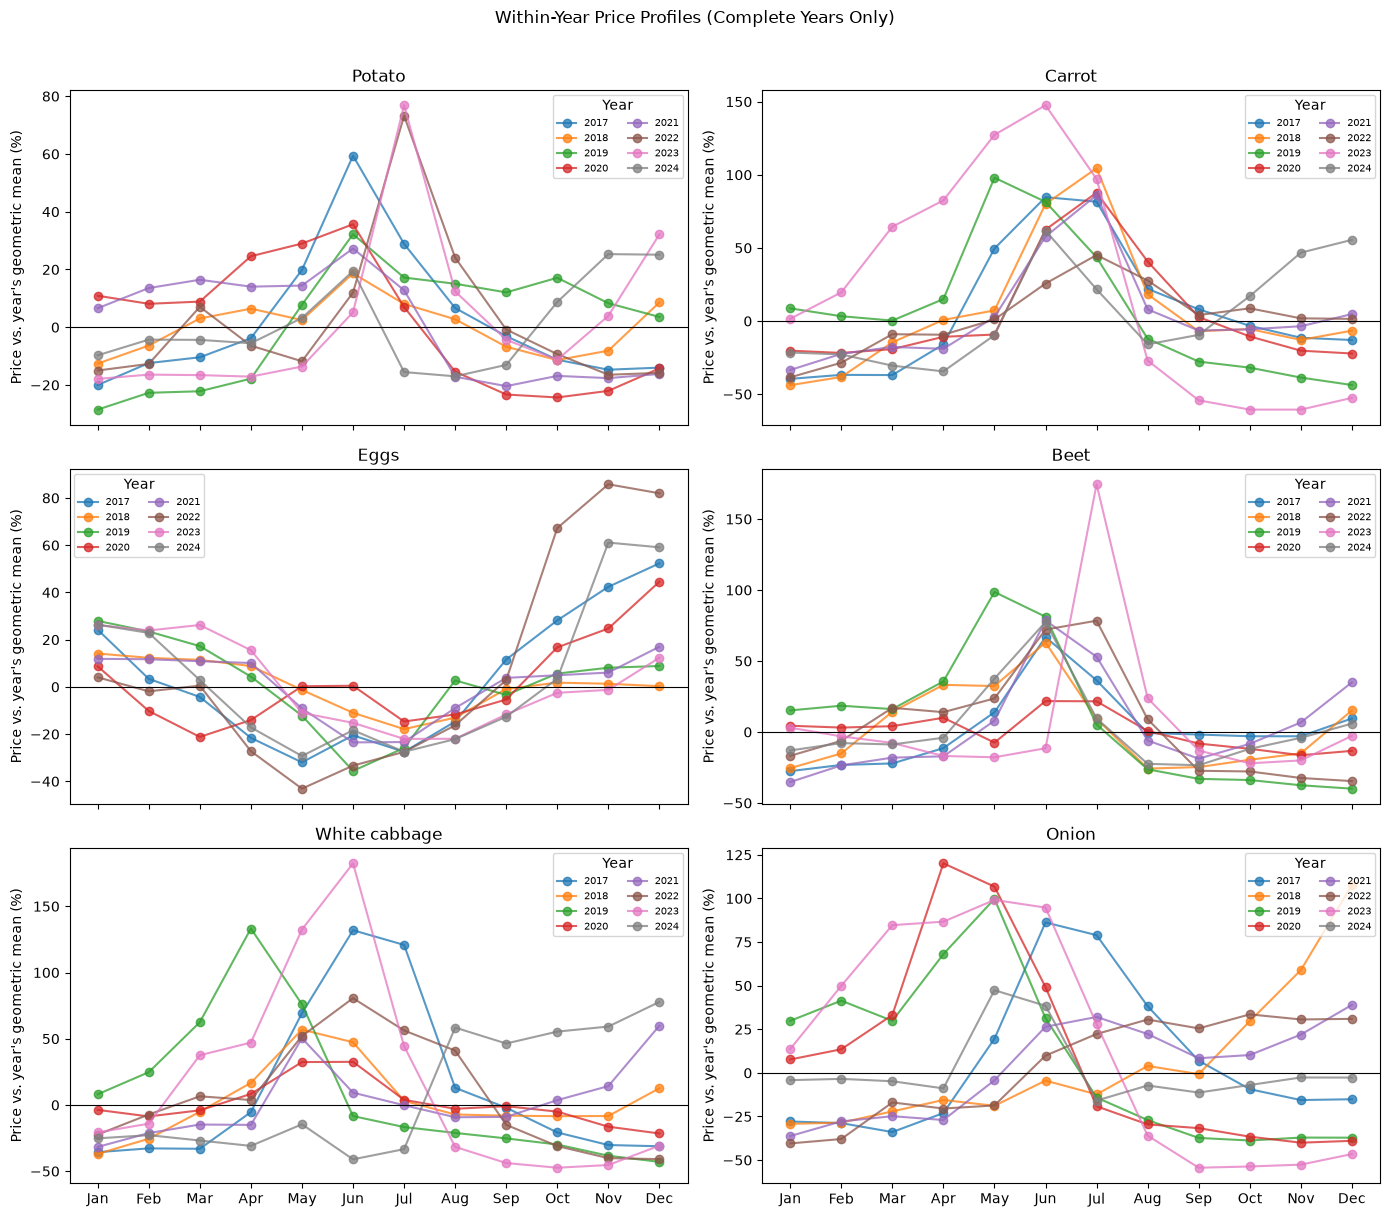

In [5]:
seasonal_plot_goods = {
    "Potato": TARGET_GOODS["Potato"], "Carrot": TARGET_GOODS["Carrot"],
    "Eggs": TARGET_GOODS["Eggs"], "Beet": OPTIMIZATION_CANDIDATES["Beet"],
    "White cabbage": OPTIMIZATION_CANDIDATES["White cabbage"],
    "Onion": OPTIMIZATION_CANDIDATES["Onion"],
}
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
month_names = [calendar.month_abbr[m] for m in range(1, 13)]
for ax, (label, good) in zip(axes.ravel(), seasonal_plot_goods.items()):
    series = prices[good].dropna().astype(float)
    for year, yearly in series.groupby(series.index.year):
        if len(yearly) != 12 or yearly.index.month.nunique() != 12:
            continue
        centered = np.exp(np.log(yearly) - np.log(yearly).mean()) - 1
        ax.plot(yearly.index.month, centered * 100, marker="o", alpha=0.75, label=str(year))
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(label)
    ax.set_ylabel("Price vs. year's geometric mean (%)")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names)
    ax.legend(title="Year", fontsize=7, ncol=2)
fig.suptitle("Within-Year Price Profiles (Complete Years Only)", y=1.01)
fig.tight_layout()
plt.show()

## 4. Inspect STL Components for Potato, Carrot, and Eggs

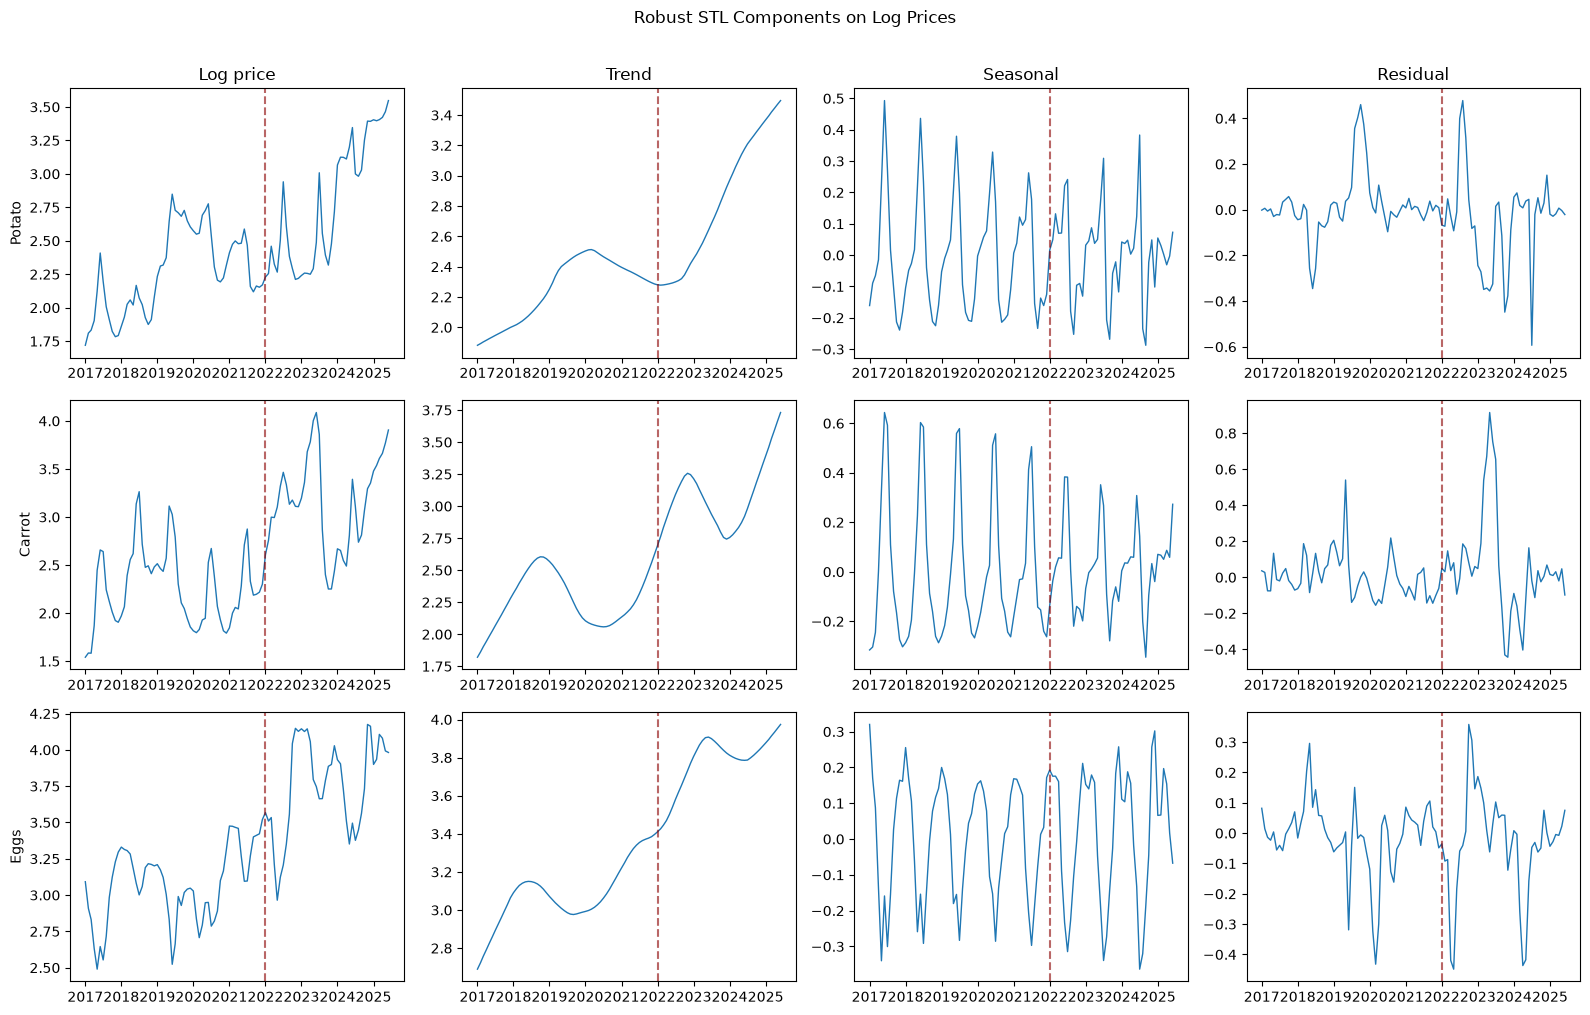

In [6]:
decomposition_goods = [TARGET_GOODS[name] for name in ["Potato", "Carrot", "Eggs"]]
fig, axes = plt.subplots(len(decomposition_goods), 4, figsize=(16, 10), sharex="row")
component_names = ["Log price", "Trend", "Seasonal", "Residual"]
for row_idx, (label, good) in enumerate(zip(["Potato", "Carrot", "Eggs"], decomposition_goods)):
    result = decompositions[good]
    components = [np.log(prices[good]), result.trend, result.seasonal, result.resid]
    for col_idx, (component, values) in enumerate(zip(component_names, components)):
        ax = axes[row_idx, col_idx]
        ax.plot(values.index, values.values, linewidth=1)
        if row_idx == 0:
            ax.set_title(component)
        if col_idx == 0:
            ax.set_ylabel(label)
        ax.axvline(pd.Timestamp("2022-01-01"), color="darkred", linestyle="--", alpha=0.6)
fig.suptitle("Robust STL Components on Log Prices", y=1.01)
fig.tight_layout()
plt.show()

## 5. Export the Seasonality Table

In [7]:
RESULT_FILE.parent.mkdir(parents=True, exist_ok=True)
export = seasonality.drop(columns=["status"], errors="ignore").rename(
    columns={"amplitude_pct": "amplitude_%"})
export.to_csv(RESULT_FILE, index=False, encoding="utf-8-sig")
print("Saved seasonality results to:", RESULT_FILE)

Saved seasonality results to: d:\УКУ\4 курс\Прогнози\проєкт\дані\results\seasonality_rank.csv


## 6. Preliminary Interpretation and Presentation Notes

The existing STL run on the 2017-01 to 2025-06 Ukraine series found materially different patterns:

| Analysis label | Seasonal strength | Trend strength | Peak month | Trough month | Estimated amplitude |
|---|---:|---:|---|---|---:|
| Potato | 0.26 | 0.86 | June | September | 62.8% |
| Carrot | 0.64 | 0.86 | July | December | 95.3% |
| Eggs | 0.57 | 0.88 | December | July | 64.2% |
| Pasteurized milk | 0.35 | 1.00 | December | June | 3.1% |
| A-95 gasoline | 0.06 | 0.96 | November | April | 5.0% |
| Sunflower oil | 0.00 | 0.93 | June | October | 6.7% |

These are descriptive estimates, not evidence of statistical significance or proof that the same pattern repeats every year. The high `F_seasonal` for milk alongside its small amplitude illustrates why both strength and magnitude matter. Cabbage and onion are useful additional diagnostics: their amplitudes can be large while their STL seasonal-strength values are low, suggesting unstable year-to-year patterns or shocks. Use the individual-year plots to check this.

Trend strength is high for most series, consistent with large changes in the general price level. Prices after 2022 include a major regime change and changing territorial coverage; use rolling-origin validation, report pre-/post-2022 performance separately, and do not interpret a seasonal decomposition as a causal explanation.

## 7. Backtesting Design and Baseline Models

Use an expanding-window rolling-origin evaluation. The initial training window is 36 months, each test window is the next 12 months, and the origin advances by 6 months. With 102 observations, this gives 10 forecast origins. At every origin, fit models and any data-dependent transformations using only the training segment; the next 12 months remain unseen until scoring. Three complete test windows end before 2022; later windows include or follow the 2022 regime break.

The current no-ML experiment compares seven methods: naive, drift, seasonal naive, seasonal naive with a year-over-year adjustment, STL plus drift, damped-trend ETS, and SARIMA. Some models fit log prices and transform forecasts back to price levels. Report MAE, RMSE, MASE, and sMAPE by product and forecast horizon; also report SARIMA convergence and regime-specific results. These are forecasting baselines, not machine-learning models.

### Bridge to Optimization

The strongly seasonal vegetables could motivate an exploratory storage/procurement planning scenario. Price forecasts alone are insufficient to optimize: additional inputs are needed for demand, purchase and selling prices, storage capacity, spoilage, operating cost, lead time, and budget. Price elasticity cannot be estimated from this dataset alone because it contains no sales quantities or demand observations.